# Procesos Gaussianos (GP)

**¿Qué estamos haciendo cuando hablamos de un proceso gaussiano?**

La idea de este capítulo es construir una intuición sobre una idea que puede resultar un poco extraña al principio: pensar una función como un objeto aleatorio.

Recordemos un proceso de regresión:

cuando hacemos una regresión, tenemos una variable respuesta $Y$ y una o más variables explicativas $X$, y queremos describir de alguna manera cómo se relacionan.

* Por ejemplo, en una regresión lineal suponemos que la relación puede escribirse como

$$Y_i=β_0+β_1X_i+ε_i$$


donde la media de $Y$ cambia linealmente con $X$.

Podemos hacer algo un poco más flexible y agregar términos cuadráticos o cúbicos:

$$Y_i=β_0+β_1X_i+β_2X_i^2+β_3X_i3$$


En todos estos casos estamos eligiendo una familia de funciones para modelar, antes de observar los datos.

¿Qué pasa si no queremos decidir de antemano cuál es la forma de la función?

No significa que no vayamos a hacer ningún supuesto. Vamos a hacer supuestos, pero van a ser de otro tipo.
Y ahí es donde aparece lo que se conoce como **Procesos Gaussianos**.

## El concepto de "Funciones Aleatorias"

Hasta ahora, cuando hacíamos inferencia bayesiana, estábamos acostumbrados a que los objetos desconocidos sean *parámetros*.

Por ejemplo, desconocemos $β_0$, $β_1$, etc., y podemos asignarles distribuciones a priori tales como: $β_0∼N(0,10)$ , $β_1∼N(0,10)$...

Entonces los parámetros se tratan igual que a las variables aleatorias.

Ahora pensemos un poco distinto: ¿Qué pasaría si el objeto aleatorio no fuera un parámetro sino directamente la función?.  Es decir, en lugar de decir "tengo una función determinada pero no conozco sus parámetros", pensamos "tengo una colección de funciones posibles y voy a asignar probabilidades a esas funciones".


Esa es la idea que hay detrás de los procesos estocásticos y, en particular, de los procesos gaussianos, donde pasamos de trabajar con parámetros aleatorios a trabajar con *funciones aleatorias*.

Es decir, el resultado aleatorio es una función completa:

antes de observar los datos podríamos tener muchas funciones posibles

$$f_1(x),f_2(x),f_3(x),…$$

y el proceso estocástico nos permite describir cómo se distribuyen esas posibles funciones.

Entonces, en lugar de tener una variable aleatoria que toma valores numéricos, tenemos algo que podemos imaginar como una "máquina" que genera funciones. Y dependiendo de cómo definamos eel proceso de construcción, algunas funciones van a ser más probables que otras.

Esto es fundamental: **el modelo va a determinar qué tipo de funciones consideramos razonables antes de observar los datos.**


Supongamos que tenemos una función aleatoria y elegimos tres puntos: $x_1,x_2,x_3$, en los que evaluamos la función y obtenemos
$f(x_1),f(x_2),f(x_3)$.

Tendremos entonces un vector de tres números con el que podemos preguntarnos cuál es la distribución conjunta de esos tres valores.

En un proceso gaussiano, esa distribución conjunta es una normal multivariada:

$$\begin{pmatrix} f(x_1)\\ f(x_2)\\ f(x_3) \end{pmatrix} \sim\mathcal N(\boldsymbol\mu,K)$$

para cierto $\mu$ y $K$ que analizaremos más adelante.

**Observación:** no estamos diciendo que "la función tenga una distribución normal" en el sentido habitual de una variable aleatoria, sino que estamos diciendo que si tomamos cualquier conjunto finito de evaluaciones de esa función, esas evaluaciones ¡tienen una distribución normal conjunta!

### Proceso Gaussiano: formalizamos

Escribimos un GP de la siguiente manera:

dados dos puntos $x$ y $x´$, y una función aleatoria o función latente $f$:

$$f(x)∼GP(m(x),k(x,x′))$$

donde:

* $m(x)$ es la función media.


* $k(x,x′)$ es la función de covarianza, que también vamos a llamar ***kernel***.

Si elegimos un conjunto de puntos $x_1,…,x_n$ entonces obtenemos un vector:
$$(f(x_1),…,f(x_n))$$

que sigue una distribución normal multivariada cuya media está dada por:
$$(m(x_1),…,m(x_n))$$

y cuya matriz de covarianzas $K$ se construye usando el kernel:
$$K_{ij}=k(x_i,x_j)$$


Veamos qué significa cada una de estas dos partes:

La función media es:

$$m(x)=E[f(x)]$$

Es decir, para cada valor de $x$, nos dice cuál es el valor promedio que esperamos para la función.

La Covarianza es:

$$k(x,x′)=Cov⁡(f(x),f(x′))$$

que nos dice cómo se relacionan los valores de la función en dos puntos distintos.

Este segundo elemento es particularmente importante en los procesos gaussianos, ya que muchas veces vamos a elegir una función media muy sencilla, incluso $m(x)=0$ pero gran parte de la estructura del modelo va a venir dada por el kernel.



### ¿Qué es un kernel?



Podemos pensar un *kernel* como una función matemática que nos indica qué tan relacionados están dos puntos.

Supongamos que tenemos dos puntos muy cercanos, es decir $x≈x′$

Es bastante razonable, si queremos modelar una función suave, pensar que:
$$f(x)≈f(x′)$$

Para conseguir este resultado, queremos que esos dos valores tengan una covarianza alta, es decir, $k(x,x′)$ grande.

En cambio, si tenemos dos puntos muy alejados, podemos hacer que la relación entre sus valores sea menor.

Entonces podemos pensar al kernel como una especie de regla  determina cómo se comportan juntas distintas partes de la función:

* si dos puntos están cerca, busco que sus valores se parezcan bastante.
* si están lejos, permito que sean más independientes.





### El kernel RBF (Radial Basis Function)

RBF o Radia Basis Function es uno de los kernel más utilizados en GP, y está dado por:

$$k(x,x′)=α^2exp⁡(\frac{-(x−x′)^2}{2ℓ^2})$$

donde:

<font color="pink"> $α$ controla la escala de las variaciones;

<font color="pink"> $l$ es la longitud de escala.

* Si $x$ y $x'$ son muy cercanos, entonces $(x−x′)^2$ es pequeño y el kernel toma un valor relativamente grande.

* Si $x$ y $x´$ están muy alejados, el exponente se hace más negativo y el kernel disminuye.

Entonces el kernel RBF está diciendo justamente que ¡puntos cercanos están fuertemente relacionados y puntos alejados están menos relacionados!

### La longitud de escala $\ell$


Supongamos primero que tenemos una longitud de escala pequeña. En ese caso, la correlación entre dos puntos cae rápidamente cuando los puntos se separan.
Entonces la función puede cambiar bastante incluso en distancias relativamente pequeñas. Por eso solemos obtener funciones más variables, con cambios más rápidos.

Ahora imaginemos una longitud de escala grande. En ese caso, dos puntos pueden estar bastante separados y todavía seguir teniendo una covarianza importante.

Por lo tanto, si la función toma un valor en un punto, esperamos que en los puntos cercanos siga teniendo valores parecidos.
El resultado son funciones más suaves.

Entonces podemos pensar:

$\ell \ \text{pequeña} → \text{más variación}$

$\ell \ \text{grande} → \text{más suavidad}$

Y esto es importante porque muestra que elegir un kernel no es una decisión puramente técnica.
Estamos incorporando supuestos sobre cómo creemos que se comporta la función.


## GP y Regresión

Hasta ahora estuvimos hablando de funciones en abstracto, pero volvamos al problema que nos interesa: cómo trabajar con un modelo de regresión.

Recordemos que tenemos:

$$f∼GP(m,k)$$

y después modelar las observaciones como:

$$Y_i∣f∼N(f(X_i),σ^2)$$


Esto es: xiste una función desconocida $f$ que representa la relación entre $X$ e $Y$. Pero, en lugar de decir que $f$ es lineal o que es un polinomio de grado tres, le asignamos una distribución sobre funciones.

Luego queda observar los datos con cierto ruido.

Podemos imaginar entonces:

$$X_i⟶f(X_i)⟶Y_i$$


Esto nos permite hacer regresión sin especificar explícitamente una forma funcional concreta para $f$.

## GP y Bayes


La lógica de trabajar con Procesos Gaussianos sigue siendo bayesiana.

Podemos escribir:

$$p(f∣y)∝p(y∣f)p(f)$$

Observen quer es exactamente la misma estructura que conocemos, tenemos un prior, que en este caso describe qué funciones consideramos plausibles antes de observar los datos, una verosimilitud que nos dice qué tan compatibles son los datos con una determinada función, y después tenemos una distribución posterior sobre las funciones.

Entonces:

* $p(f)$ representa las funciones plausibles antes de ver los datos.
* $p(y∣f)$ nos dice qué tan bien una determinada función explica los datos.
* $p(f∣y)$ representa las funciones plausibles después de incorporar la información de los datos.

La diferencia fundamental con los modelos que veníamos trabajando es que ahora el objeto desconocido no es solamente un vector de parámetros.
El objeto desconocido es una función.

### Veamos un ejemplo de uso de RBF

En Procesos Gaussianos el kernel (o función de covarianza) nos permite estudiar la suavidad de la función $f$:

El kernel responde la siguiente pregunta: ¿Cuánto deberían parecerse los valores de la función en dos puntos cercanos?


Si el kernel impone mucha dependencia:

* puntos cercanos tienen valores muy parecidos
* las funciones son suaves

Si impone poca dependencia:

* los valores pueden variar rápidamente
* aparecen funciones más rugosas


**cambio de escala**

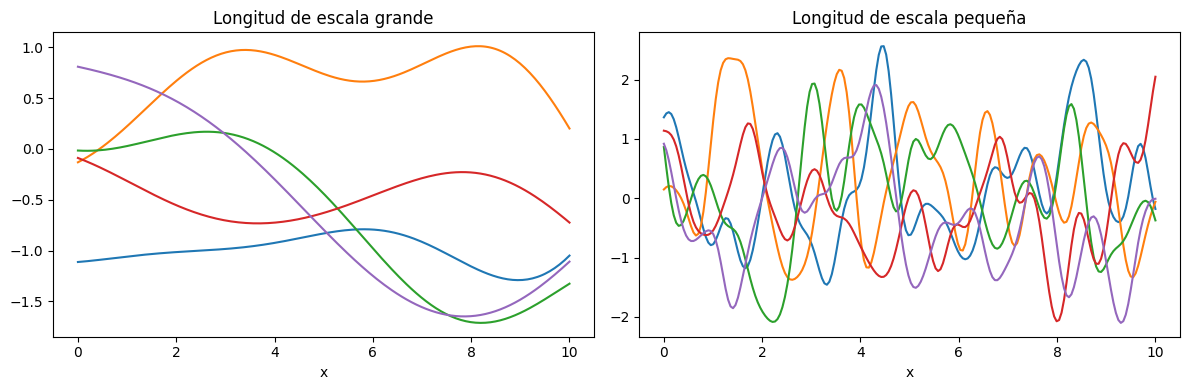

In [ ]:
# @title
def kernel_rbf(x1, x2, l):
    sqdist = (x1[:,None]-x2[None,:])**2
    return np.exp(-sqdist/(2*l**2))

x = np.linspace(0,10,200)

fig, ax = plt.subplots(1,2, figsize=(12,4))

for l, panel, titulo in [
    (3.0, 0, "Escala grande"),
    (0.3, 1, "Escala pequeña")
]:

    K = kernel_rbf(x,x,l)

    muestras = np.random.multivariate_normal(
        np.zeros(len(x)),
        K,
        size=5
    )

    for m in muestras:
        ax[panel].plot(x,m)

    ax[panel].set_title(titulo)
    ax[panel].set_xlabel("x")

plt.tight_layout()
plt.show()

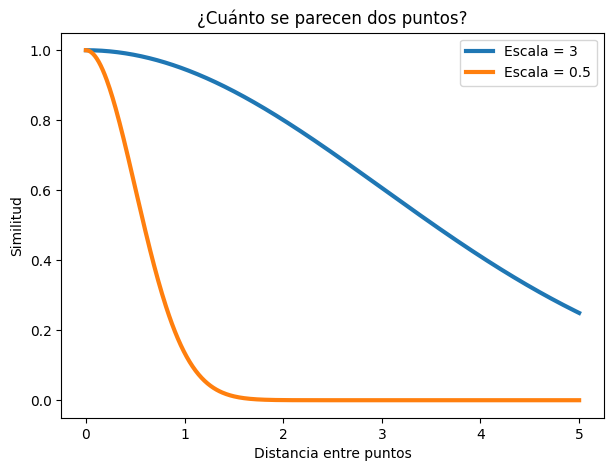

In [ ]:
d = np.linspace(0,5,500)

rho1 = np.exp(-(d**2)/(2*3**2))
rho2 = np.exp(-(d**2)/(2*0.5**2))

plt.figure(figsize=(7,5))

plt.plot(d, rho1, lw=3,
         label="Escala = 3")

plt.plot(d, rho2, lw=3,
         label="Escala = 0.5")

plt.xlabel("Distancia entre puntos")
plt.ylabel("Similitud")
plt.title("¿Cuánto se parecen dos puntos?")
plt.legend()

plt.show()

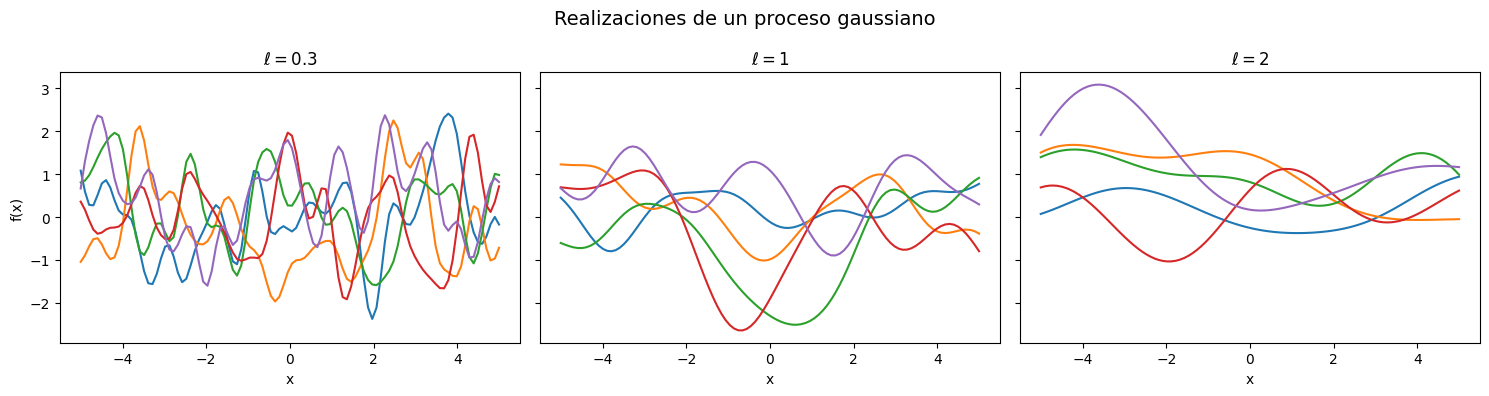

In [ ]:
x = np.linspace(-5, 5, 100)

# Kernel RBF
def rbf_kernel(x1, x2, alpha=1, ell=1):
    distancia = x1[:, None] - x2[None, :]
    return alpha**2 * np.exp(
        -distancia**2 / (2 * ell**2)
    )

valores_ell = [0.3, 1, 2]

titulos = [
    r"$\ell = 0.3$",
    r"$\ell = 1$",
    r"$\ell = 2$"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    sharey=True
)

for ax, ell, titulo in zip(axes, valores_ell, titulos):

    K = rbf_kernel(x, x, ell=ell)
    funciones = np.random.multivariate_normal(
        mean=np.zeros(len(x)),
        cov=K,
        size=5
    )

    for f in funciones:
        ax.plot(x, f)

    ax.set_title(titulo)
    ax.set_xlabel("x")

axes[0].set_ylabel("f(x)")

plt.suptitle(
    "Realizaciones de un proceso gaussiano",
    fontsize=14
)

plt.tight_layout()
plt.show()

¿qué relación encuentran entre la longitud de escala y la suavidad de las funciones?

Observen que a medida que aumenta el tamaño de $\ell$, las realizaciones del GP se vuelven más suaves.

#### **Ejemplo con datos sintéticos:**

**Generamos datos no lineales**

Primero vamos a construir un problema en el que conocemos la función verdadera.

In [ ]:
# Semilla para poder reproducir los resultados
rng = np.random.default_rng(123)

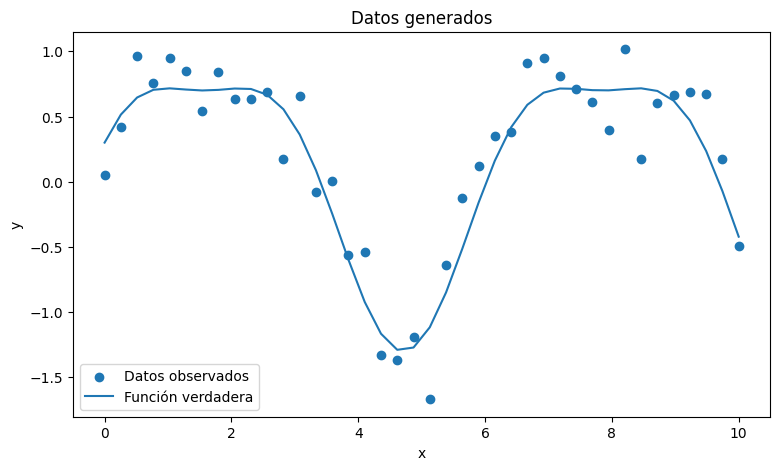

In [ ]:
n = 40
x = np.linspace(0, 10, n)

# Función verdadera
f_real = np.sin(x) + 0.3 * np.cos(2 * x)

# Ruido observado
ruido = rng.normal(0, 0.25, size=n)

# Datos observados
y = f_real + ruido

plt.figure(figsize=(9, 5))

plt.scatter(x, y, label="Datos observados")
plt.plot(x, f_real, label="Función verdadera")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Datos generados")
plt.legend()
plt.show()

**Nuestro primer modelo de Proceso Gaussiano**

Ahora vamos a plantear:
$$ y_i\sim N(f(x_i),\sigma)$$

donde

$$ f(x)\sim GP(0,k). $$

En PyMC podemos escribirlo directamente.

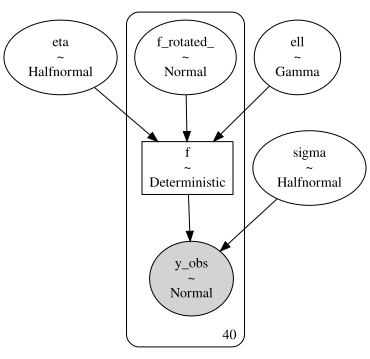

In [ ]:
with pm.Model() as modelo_gp:

    # Prior para la amplitud de las variaciones
    eta = pm.HalfNormal("eta", sigma=1)

    # Prior para la longitud de escala
    ell = pm.Gamma("ell", alpha=2, beta=1)

    # Kernel RBF
    k = eta**2 * pm.gp.cov.ExpQuad(
        input_dim=1,
        ls=ell
    )

    # Proceso gaussiano
    gp = pm.gp.Latent(
        mean_func=pm.gp.mean.Zero(),
        cov_func=k
    )

    # Valores latentes de la función en los datos observados
    f = gp.prior("f", X=x[:, None])

    # Desvío estándar del ruido
    sigma = pm.HalfNormal("sigma", sigma=0.5)

    # Modelo para los datos
    y_obs = pm.Normal(
        "y_obs",
        mu=f,
        sigma=sigma,
        observed=y
    )

#visualizamos el modelo
pm.model_to_graphviz(modelo_gp)

**Ajustamos el modelo**

In [ ]:
with modelo_gp:

    idata_gp = pm.sample(
        draws=1000,
        tune=1000,
        chains=2,
        random_seed=123,
        target_accept=0.9
    )

Output()

ERROR:pymc.stats.convergence:There were 15 divergences after tuning. Increase `target_accept` or reparameterize.


NOTA: En este ejemplo sintético NO daremos tratamiento a las divergencias

**¿Qué aprendió el modelo?**

Primero podemos mirar los hiperparámetros:

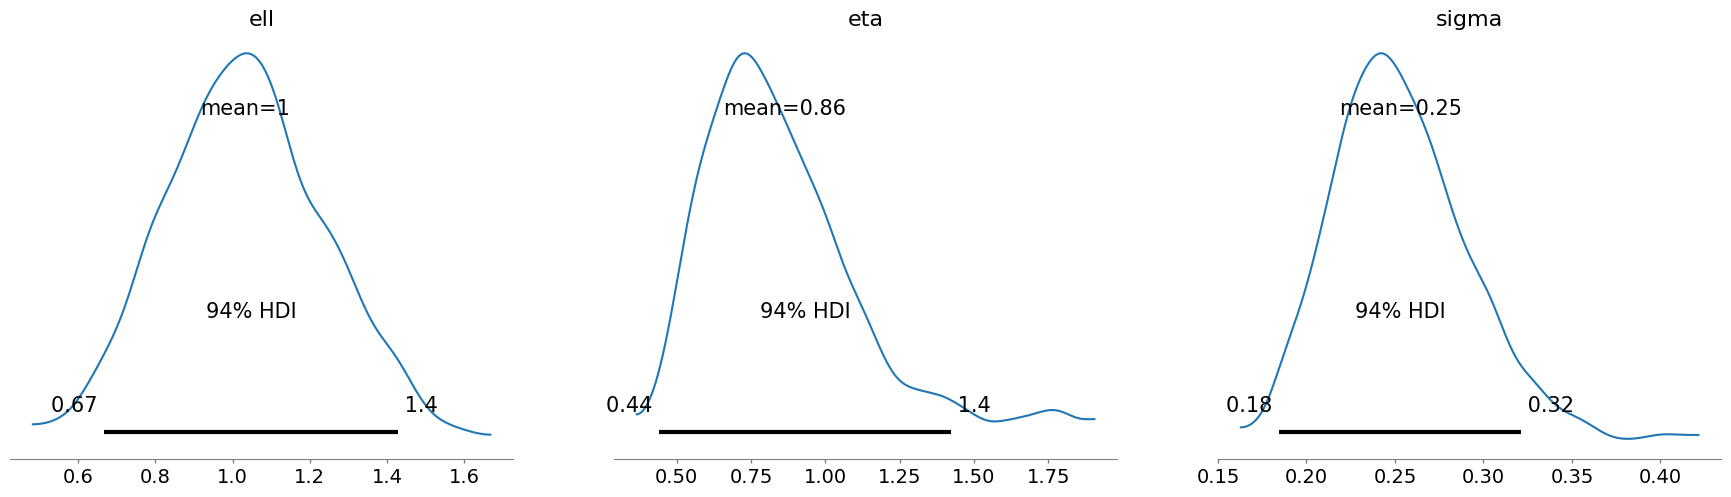

In [ ]:
az.plot_posterior(
    idata_gp,
    var_names=["ell", "eta", "sigma"]
)

plt.show()

Observen que aparecen tres cantidades importantes:

<font color="violet"> $\ell$: longitud de escala;

<font color="violet"> $\eta$: amplitud de las variaciones;

<font color="violet"> $\sigma$: ruido de las observaciones.

No solamente estamos estimando la función. También estamos aprendiendo cuáles son las características de las funciones que mejor explican los datos...


**Estudiemos la posterior de la función**

Ahora queremos visualizar $f(x)$.

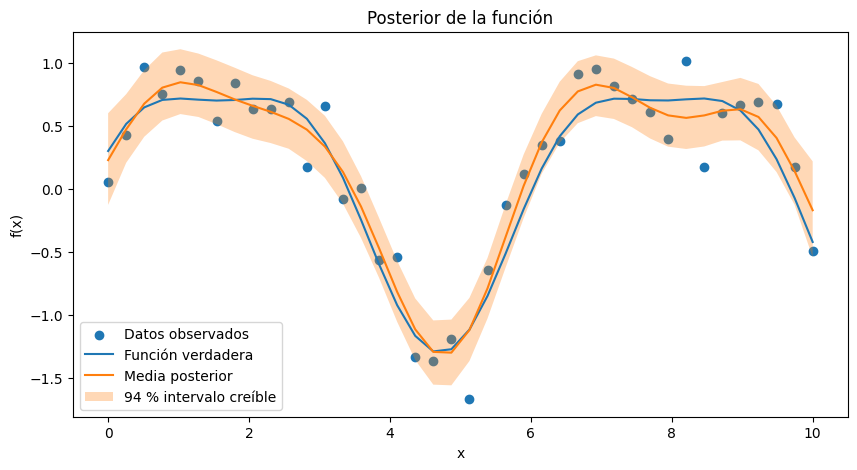

In [ ]:
# Extraemos las muestras posteriores de f:
f_post = idata_gp.posterior["f"]

f_samples = f_post.stack(sample=("chain", "draw")).values

f_mean = f_samples.mean(axis=1)

# 94 % creíble
f_low = np.quantile(f_samples, 0.03, axis=1)
f_high = np.quantile(f_samples, 0.97, axis=1)

plt.figure(figsize=(10, 5))
plt.scatter(
    x,
    y,
    label="Datos observados"
)
plt.plot(
    x,
    f_real,
    label="Función verdadera"
)
plt.plot(
    x,
    f_mean,
    label="Media posterior"
)
plt.fill_between(
    x,
    f_low,
    f_high,
    alpha=0.3,
    label="94 % intervalo creíble"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Posterior de la función")
plt.legend()
plt.show()

**Actividad:**

¿Dónde hay mayor incertidumbre?

¿Dónde los datos están ayudando más al modelo?

¿Qué ocurre entre los puntos observados?


**Predicción en nuevos valores**

No solamente queremos recuperar la función donde tenemos datos, sino que también nos interesa predecir en valores nuevos.

Vamos a crear un nuevo conjunto de valores para los que queremos predecir:

In [ ]:
x_new = np.linspace(-1, 11, 150)

Trabajaremos con `gp.conditional` para poder realizar las predicciones. Creamos el modelo y realizamos el muestreo de la distribución posterior predictiva, para luego extraer dichas muestras:

In [ ]:
with modelo_gp:

    # Función latente en los nuevos valores
    f_new = gp.conditional(
        "f_new",
        Xnew=x_new[:, None]
    )

    # Obtenemos un muestreo de la distribución posterior predictiva
    idata_pred = pm.sample_posterior_predictive(
        idata_gp,
        var_names=["f_new"],
        predictions=True,
        random_seed=123
    )

Output()

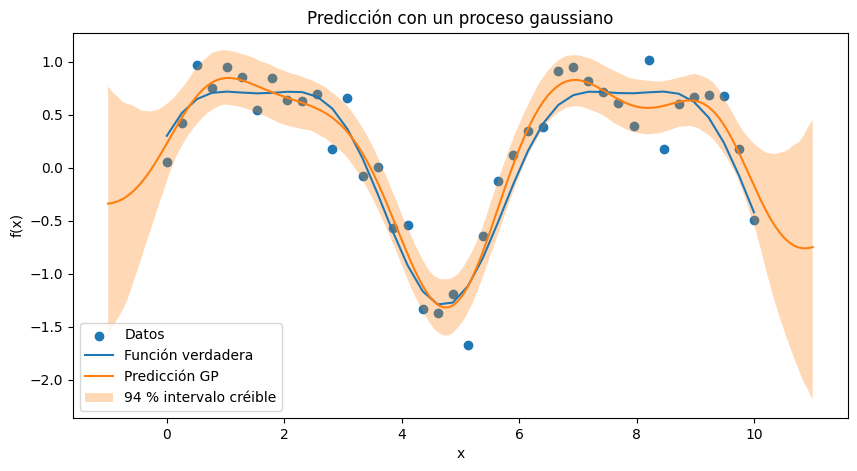

In [ ]:
# Extraemos las muestras predictivas
f_new_samples = (
    idata_pred.predictions["f_new"]
    .stack(sample=("chain", "draw"))
    .values
)

# Media predictiva
f_new_mean = f_new_samples.mean(axis=1)

# 94% creíble
f_new_low = np.quantile(
    f_new_samples,
    0.03,
    axis=1
)

f_new_high = np.quantile(
    f_new_samples,
    0.97,
    axis=1
)

plt.figure(figsize=(10, 5))
plt.scatter(
    x,
    y,
    label="Datos"
)
plt.plot(
    x,
    f_real,
    label="Función verdadera"
)
plt.plot(
    x_new,
    f_new_mean,
    label="Predicción GP"
)
plt.fill_between(
    x_new,
    f_new_low,
    f_new_high,
    alpha=0.3,
    label="94 % intervalo créible"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Predicción con un proceso gaussiano")
plt.legend()
plt.show()

**¿Qué pasa con la longitud de escala?**

Veamos qué significa visualmente trabajar con $\ell$. Para eso vamos a generar funciones provenientes de distintos kernels RBF:

In [ ]:
def matriz_kernel_rbf(x, ell, eta=1):
    """
    Construye una matriz de covarianzas RBF.
    """

    # Distancias entre todos los pares de valores de x
    distancia = x[:, None] - x[None, :]

    # Kernel RBF
    k = eta**2 * np.exp(
        -0.5 * (distancia / ell)**2
    )

    return k

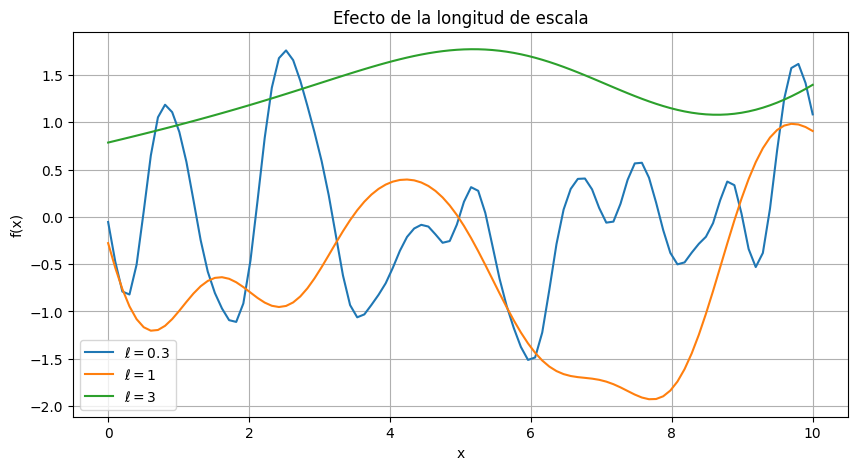

In [ ]:
# Creamos una grilla de valores donde vamos a evaluar
# las funciones.
x_grid = np.linspace(0, 10, 100)
# Vamos a comparar tres valores diferentes de la longitud
# de escala.
longitudes = [0.3, 1, 3]
plt.figure(figsize=(10, 5))

for ell in longitudes:
    # Construimos la matriz de covarianzas correspondiente
    # al valor actual de ell.
    K = matriz_kernel_rbf(x_grid,  ell=ell  )
    # Generamos una realización aleatoria del proceso gaussiano.
    # La media es cero y la matriz K determina cómo se
    # relacionan los valores de la función.
    f_sample = rng.multivariate_normal(
        mean=np.zeros(len(x_grid)),  cov=K )
    # Graficamos la función generada.
    plt.plot( x_grid, f_sample, label=f"$\\ell={ell}$" )

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Efecto de la longitud de escala")
plt.legend()
plt.grid(True)
plt.show()

¡Esto es exactamente lo que ya vimos cuando introdujimos el RBF!

Ahora vemos porqué este parámetro es tan importante cuando usamos un GP como modelo.

# Extensiones del Proceso Gaussiano


Una vez que tenemos un proceso gaussiano que nos permite modelar una función flexible, ¿qué podemos hacer con esa función?

Trabajaremos vvarias aplicaciones que, a primera vista, pueden parecer temas completamente distintos:

* regresión,
* clasificación,
* conteos,
* datos espaciales,
* procesos de puntos
* HSGP.

Pero en realidad hay una misma estructura detrás de todos ellos: son distintas maneras de utilizar una misma función latente modelada mediante un proceso gaussiano.

Partimos entonces de lo que ya conocemos:

$$f(x)∼GP(m(x),k(x,x′))$$

Esto significa que no estamos especificando una forma concreta para la función $f$: no decimos que $f$ sea una recta, ni un polinomio de grado dos, ni una función determinada.

En cambio, especificamos una distribución sobre funciones posibles, y el kernel es el que nos dice qué tipo de funciones consideramos razonables.


Supongamos que tenemos esta función $f$, **¿qué hacemos con ella?**

Podemos usarla para explicar una variable continua, para modelar una respuesta binaria, una variable de conteo, una estructura espacial o incluso la intensidad de un proceso de puntos. En todos los casos la función $f$ sigue siendo el elemento común.


Supongamos que no conocemos la longitud de escala.

En lugar de fijarla arbitrariamente, podemos darle un prior:

$$l∼p(l)$$

También podemos hacer lo mismo con la amplitud:
$$α∼p(α)$$

Entonces nuestro modelo completo tiene varias capas.

Tenemos los parámetros del kernel, tenemos el proceso gaussiano condicionado a esos parámetros

$$f ∼ GP(0, k_{α,l})$$

y tenemos finalmente los datos para realizar las actualizaciones correspontiendes.

Y después de observar los datos, podemos obtener la distribución posterior de todas estas cantidades.

$$Y_i ∼ N(f (x_i), σ^2)$$


No solamente estamos aprendiendo cuál es la función que explica los datos, sino que también podemos aprender características de esa función.

Por ejemplo, podemos aprender qué valores de la longitud de escala son compatibles con los datos.

**¿qué significa poner un prior sobre la longitud de escala?**

* Si le damos un prior demasiado concentrado en valores muy pequeños, estamos diciendo que antes de observar los datos consideramos plausibles funciones con cambios muy rápidos.
* Si lo concentramos en valores muy grandes, estamos favoreciendo funciones mucho más suaves.

Por eso el prior sobre $\ell$ tiene una interpretación concreta, porque nos permite definir qué escalas de variación consideramos razonables antes de mirar los datos, para luego con los datos actualizan esa información.

Podemos escribirlo de la misma manera que en cualquier otro modelo bayesiano:

$$p(\ell∣y)∝p(y∣\ell)p(\ell)$$


## GP generalizado

### ¿Qué pasa si nuestra variable respuesta no es continua?

Hasta ahora escribimos:

$$Y_i∼N(f(x_i),σ^2)$$

Pero no hay ninguna razón para que $Y_i$ tenga que seguir una distribución Normal. Por ejemplo, podríamos tener que $Y$ es una variable binaria o de conteo.

En esos casos, la distribución de $Y$ tiene que cambiar.

En lugar de conectar directamente $f(x)$ con la media de $Y$, utilizamos una función de enlace:

$$g(μ_i)=f(x_i)$$

Observen que el GP sigue modelando la función latente $f$, pero tenemos otra forma en la que esa función se conecta con la respuesta $Y$.

Por ejemplo,

* Si la respuesta sigue una distribución Normal, podemos utilizar el enlace identidad.
* Si sigue una Bernoulli, podemos utilizar el enlace logit.
* Si sigue una Poisson, podemos utilizar el enlace log.


### GP para clasificación

Supongamos que queremos predecir una variable que solamente puede tomar los valores cero o uno.

Tenemos:

$$Y_i∼Bernoulli(p_i)$$.

Como ya sabemos, la probabilidad $p_i$ tiene que estar entre cero y uno, por lo que entonces no podemos simplemente decir que $p_i=f(x_i)$ porque $f(x_i)$ puede tomar cualquier valor real.

Utilizaremos entonces la función de enlace *logit*, quedando parte del modelo de esta manera:

$$logit⁡(_pi)=f(x_i).$$

O, equivalentemente:

$$p_i=\frac{1}{1+\exp[-f(x_i)]}.$$

$f(x)$ sigue siendo una función continua y flexible, pero después de pasar por la función logística obtenemos una probabilidad adecuadamente.

Entonces podemos tener una probabilidad de pertenecer a una clase que cambia de manera no lineal con $x$, es decir, no tuvimos que especificar que la frontera fuera una recta.





## Cox GP

Supongamos que estamos observando eventos que ocurren en el espacio, por ejemplo, ubicaciones donde ocurrió determinado fenómeno a estudiar.

En ese caso podemos estar interesados no tanto en predecir una respuesta $Y$, sino en modelar la intensidad con la que aparecen los eventos.

Trabajemos con esa intensidad con la función $\lambda(s)$. Como una intensidad tiene que ser positiva, podemos trabajar en consecuencia con:

$$log(⁡λ(s))=f(s).$$

Y nuevamente $f(s)$ puede seguir un proceso gaussiano.

Esto se conoce como un ***proceso de Cox log-Gaussiano***.

* En algunas regiones del espacio, $f(s)$ puede ser mayor y entonces la intensidad $λ(s)$ será mayor.

* En otras regiones, $f(s)$ será menor y tendremos una menor concentración esperada de eventos.


### GP para datos espaciales


Hasta ahora escribíamos $f(x)$ para $x$ un valor real, pero no hay ninguna razón para que la entrada de $f$ tenga una sola dimensión.

Podemos tener una ubicación espacial $s=(s_1,s_2)$, y entonces modelar

$$f(s)∼GP(m(s),k(s,s′))$$

El principio es exactamente el mismo, solo que el kernel ahora mide la similitud entre ubicaciones:

* si dos puntos están cerca, podemos considerar razonable que sus valores de $f$ sean parecidos.

* si están muy alejados, esa similitud puede disminuir.

Entonces podemos obtener una superficie espacial y estudiar qué distribución utilizar para las observaciones.

i) Podemos tener una respuesta continua:

$$Y_i∼N(f(s_i),σ²)$$

ii) Podríamos tener clasificación, conteos u otras respuestas.




## Hilbert Space Gaussian Processes (HSGP)

Hasta ahora estamos hablando de una herramienta muy flexible, pero ya vimos durante todo el curso que esa flexibilidad tiene un costo.

Los procesos gaussianos exactos pueden volverse computacionalmente costosos cuando tenemos muchos datos. Entonces *¿qué hacemos si queremos mantener esta idea, pero necesitamos una representación más eficiente?*

Una posibilidad es aproximar la función, es decir, en lugar de trabajar directamente con el GP completo, podemos representar aproximadamente la función mediante una cantidad finita de funciones base:

$$f(x)≈\sum_{j=1}^m β_j ϕ_j(x).$$

donde $\beta_j$ son coeficientes y $\phi_j$ funciones que resultan de la aproximación.

La idea es parecida a muchas otras aproximaciones que ya hemos visto.
En lugar de trabajar con un objeto potencialmente muy grande, buscamos una representación mediante un número limitado de componentes. En particular, los modelos dados por HSGP, utilizan justamente esta idea para obtener una aproximación computacionalmente más eficiente de un proceso gaussiano.



# Ejemplos prácticos - casos típicos

Veamos ejemplos de casos típicos de aplicación de GP:

### Aplicación a casos de clasificación

Veamos cómo cambia un modelo GP en casos de clasificación, especialmente cómo cambia la distribución de la respuesta y la función de enlace.

Para eso vamos a generar datos de tipo binarios siguiendo el siguiente caso:

$$ f(x)=2\sin(x) $$ $$ p(x)=\operatorname{logit}^{-1}\big(f(x)\big) =\frac{1}{1+e^{-f(x)}} $$
$$y_i∼Bernoulli\big(p(x_i)\big).$$

In [ ]:
# Probabilidad verdadera
p_real = 1 / (1 + np.exp(-2 * np.sin(x)))

# Variable binaria
y_bin = rng.binomial(
    n=1,
    p=p_real
)


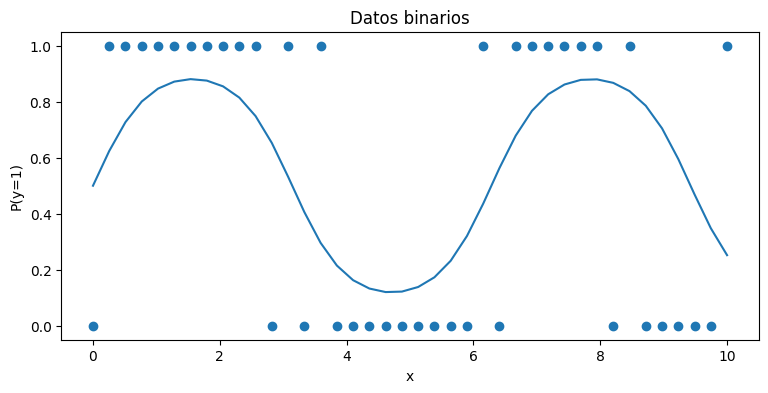

In [ ]:
plt.figure(figsize=(9, 4))

plt.scatter(
    x,
    y_bin
)

plt.plot(
    x,
    p_real
)

plt.xlabel("x")
plt.ylabel("P(y=1)")
plt.title("Datos binarios")
plt.show()

Ahora el modelo será:

$$ y_i\sim Bernoulli(p_i) $$ $$ \operatorname{logit}(p_i)=f(x_i) $$

$$ f(x)\sim GP(0,k). $$


In [ ]:
with pm.Model() as modelo_clasificacion:

    # Prior para la amplitud
    eta = pm.HalfNormal(
        "eta",
        sigma=1
    )

    # Prior para la longitud de escala
    ell = pm.Gamma(
        "ell",
        alpha=2,
        beta=1
    )

    # Kernel RBF
    k = eta**2 * pm.gp.cov.ExpQuad(
        input_dim=1,
        ls=ell
    )

    # GP latente
    gp = pm.gp.Latent(
        mean_func=pm.gp.mean.Zero(),
        cov_func=k
    )

    # Función latente
    f = gp.prior(
        "f",
        X=x[:, None]
    )

    # Probabilidad mediante el enlace logit
    p = pm.math.sigmoid(f)

    # Observaciones binarias
    y_obs = pm.Bernoulli(
        "y_obs",
        p=p,
        observed=y_bin
    )

Y al igual que siempre, generamos el muestreo correspondiente:

In [ ]:
with modelo_clasificacion:

    idata_clasificacion = pm.sample(
        draws=500,
        tune=500,
        chains=2,
        random_seed=123,
        target_accept=0.9
    )

Output()

NOTA: el GP sigue modelando una función latente, pero observen que lo único que cambió es cómo conectamos esa función con la variable observada.

### De clasificación a conteos


¿Y si la respuesta es un conteo?, la misma estructura puede utilizarse con una distribución Poisson:

$$
y_i \sim \operatorname{Poisson}(\lambda_i)
$$

$$
\log(\lambda_i)=f(x_i).
$$

Por lo tanto:

$$
\lambda_i=\exp(f(x_i)).
$$

Observen que la función latente sigue siendo un GP, pero lo que cambia es la distribución de los datos y la función de enlace.

### GP espacial - ejemplo sintético

¿Qué pasa si $x$ es una posición?



In [ ]:
# Generamos posiciones en dos dimensiones
n = 150

s1 = rng.uniform(0, 10, n)
s2 = rng.uniform(0, 10, n)

# Superficie verdadera
z = (
    np.sin(s1 / 1.5)
    + np.cos(s2 / 2)
)

# Ruido
z_obs = z + rng.normal(
    0,
    0.3,
    n
)


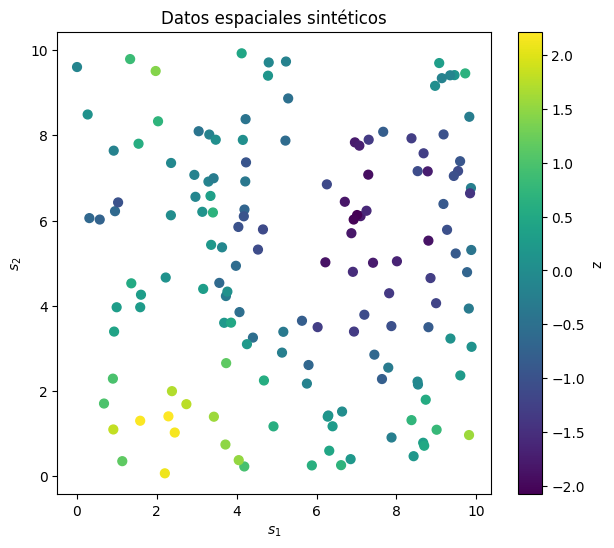

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    s1,
    s2,
    c=z_obs,
    s=40
)

plt.xlabel("$s_1$")
plt.ylabel("$s_2$")
plt.title("Datos espaciales sintéticos")
plt.colorbar(label="z")

plt.show()

Ahora la entrada del GP tiene dos dimensiones. El kernel ya no compara simplemente dos valores $x$, sino dos ubicaciones.

### Procesos de Cox de puntos espaciales:

Recordemos el modelo:

$$
N(s)\sim\operatorname{Poisson}(\lambda(s))
$$

podemos definir:

$$
\log\lambda(s)=f(s)
$$

con

$$
f(s)\sim GP(m,k).
$$

Por lo tanto:

$$
f(s)
\longrightarrow
\lambda(s)=\exp(f(s))
\longrightarrow
\text{puntos}.
$$

¡La diferencia con la regresión espacial es que ahora
el GP controla una **intensidad espacial**!

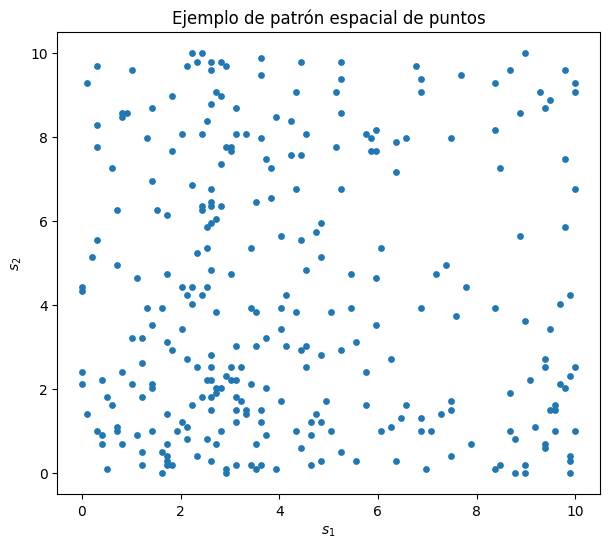

In [ ]:
# Generamos una grilla espacial
grid = np.linspace(0, 10, 100)

X, Y = np.meshgrid(
    grid,
    grid
)

# Intensidad espacial
log_lambda = (
    1
    + 0.8 * np.sin(X / 1.5)
    + 0.6 * np.cos(Y / 2)
)

lambda_xy = np.exp(log_lambda)

# Muestreamos cantidad de eventos por celda
eventos = rng.poisson(
    lambda_xy * 0.01
)

# damos cooordenadas de las celdas con eventos
idx = np.where(eventos > 0)

x_eventos = X[idx]
y_eventos = Y[idx]

plt.figure(figsize=(7, 6))

plt.scatter(
    x_eventos,
    y_eventos,
    s=15
)

plt.xlabel("$s_1$")
plt.ylabel("$s_2$")
plt.title("Ejemplo de patrón espacial de puntos")

plt.show()

Observen que los puntos no tienen por qué estar distribuidos uniformemente...

### Hilbert Space Gaussian Processes (HSGP):

En un GP exacto trabajamos directamente con la estructura de
covarianza entre las observaciones, pero para grandes cantidades de datos esto puede ser muy costoso. Entonces, una alternativa es aproximar:

$$
f(x)
\approx
\sum_{j=1}^{m}
\beta_j\phi_j(x).
$$



In [ ]:
with pm.Model() as modelo_hsgp:

    # Prior para la amplitud
    eta = pm.HalfNormal(
        "eta",
        sigma=1
    )

    # Longitud de escala
    ell = pm.Gamma(
        "ell",
        alpha=2,
        beta=1
    )

    # Aproximación HSGP
    gp = pm.gp.HSGP(
        m=[20],
        c=2,
        cov_func=eta**2 * pm.gp.cov.ExpQuad(
            input_dim=1,
            ls=ell
        )
    )

    # Función aproximada
    f = gp.prior(
        "f",
        X=x[:, None]
    )

    # Ruido
    sigma = pm.HalfNormal(
        "sigma",
        sigma=0.5
    )

    # Observaciones
    y_obs = pm.Normal(
        "y_obs",
        mu=f,
        sigma=sigma,
        observed=y
    )

Observen que la sintaxis del modelo cambia, pero conceptualmente seguimos haciendo lo mismo, es decir, modelamos una función latente flexible.